In [1]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print(root)
    if len(files) > 0:
        print("Files:", files[:5])
    print("-"*80)


/kaggle/input
--------------------------------------------------------------------------------
/kaggle/input/datasets
--------------------------------------------------------------------------------
/kaggle/input/datasets/amitsinghchauhanai
--------------------------------------------------------------------------------
/kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark
--------------------------------------------------------------------------------
/kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_infrared
Files: ['data.yaml']
--------------------------------------------------------------------------------
/kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_infrared/labels
--------------------------------------------------------------------------------
/kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_infrared/labels/val
Files: ['20190926_195921_1_5_000060.txt', '20190926_142435_1_9_000

In [2]:
!pip install -q ultralytics supervision roboflow opencv-python pyyaml pandas matplotlib seaborn tqdm
!pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu121

import os
import gc
import cv2
import torch
import numpy as np
import pandas as pd
import supervision as sv
from pathlib import Path
from tqdm import tqdm
import matplotlib.pyplot as plt
from ultralytics import YOLO
import ultralytics

ultralytics.checks()

print("=" * 50)
print(f"PyTorch version : {torch.__version__}")
print(f"CUDA available  : {torch.cuda.is_available()}")
print(f"CUDA devices    : {torch.cuda.device_count()}")
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f"  GPU {i} : {torch.cuda.get_device_name(i)}")
print("=" * 50)

os.environ["CUDA_VISIBLE_DEVICES"] = "0,1"
DEVICE_0 = "cuda:0"
DEVICE_1 = "cuda:1"

ROOT = "/kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark"
RGB_DIR = f"{ROOT}/yolo_dataset_visible"
IR_DIR = f"{ROOT}/yolo_dataset_infrared"
OUT_DIR = "/kaggle/working"
MODELS_DIR = f"{OUT_DIR}/models"
os.makedirs(MODELS_DIR, exist_ok=True)

print(f"RGB dataset : {RGB_DIR}")
print(f"IR  dataset : {IR_DIR}")
print(f"Output dir  : {OUT_DIR}")


Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
Setup complete ✅ (4 CPUs, 31.3 GB RAM, 7087.2/8156.9 GB disk)
PyTorch version : 2.11.0+cu128
CUDA available  : True
CUDA devices    : 2
  GPU 0 : Tesla T4
  GPU 1 : Tesla T4
RGB dataset : /kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_visible
IR  dataset : /kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_infrared
Output dir  : /kaggle/working


RGB data.yaml : {'names': ['uav'], 'nc': 1, 'path': '/kaggle/working/yolo_dataset_visible', 'test': 'images/test', 'train': 'images/train', 'val': 'images/val'}
IR  data.yaml : {'names': ['uav'], 'nc': 1, 'path': '/kaggle/working/yolo_dataset_infrared', 'test': 'images/test', 'train': 'images/train', 'val': 'images/val'}

RGB split counts (imgs, lbls):
  train: imgs=14972  lbls=14972
  val  : imgs= 6208  lbls= 6208
  test : imgs= 8547  lbls= 8547
IR  split counts (imgs, lbls):
  train: imgs=14972  lbls=14972
  val  : imgs= 6208  lbls= 6208
  test : imgs= 8547  lbls= 8547

RGB class hist: {0: 28047}
IR  class hist: {0: 29329}


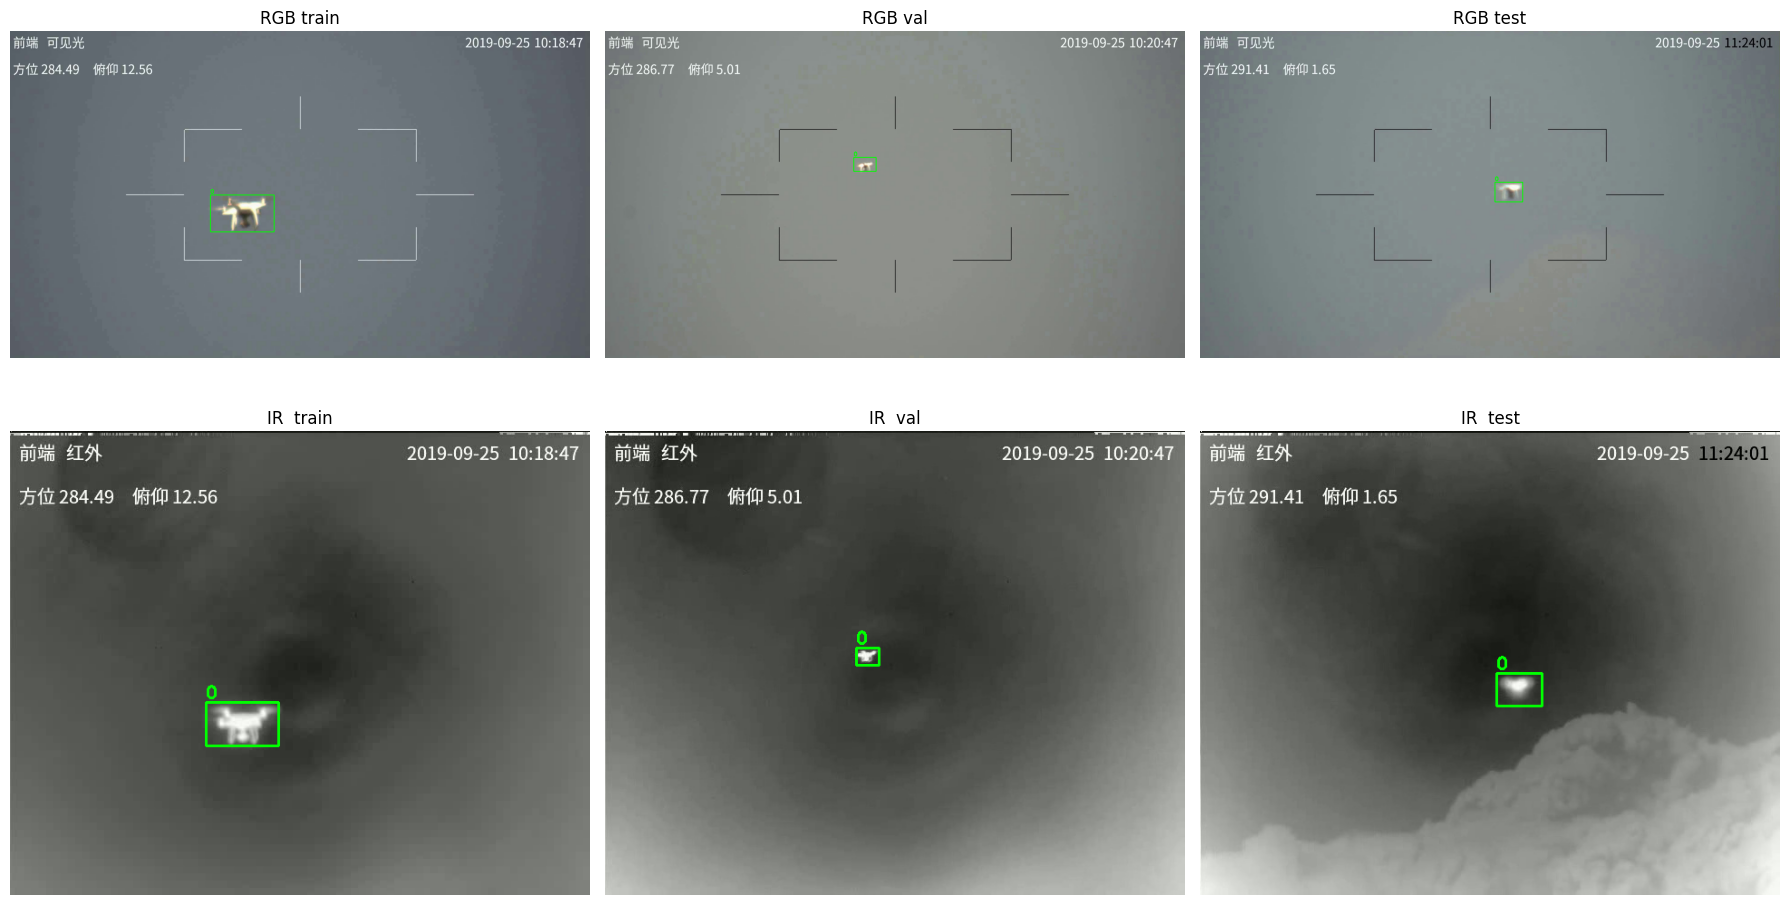

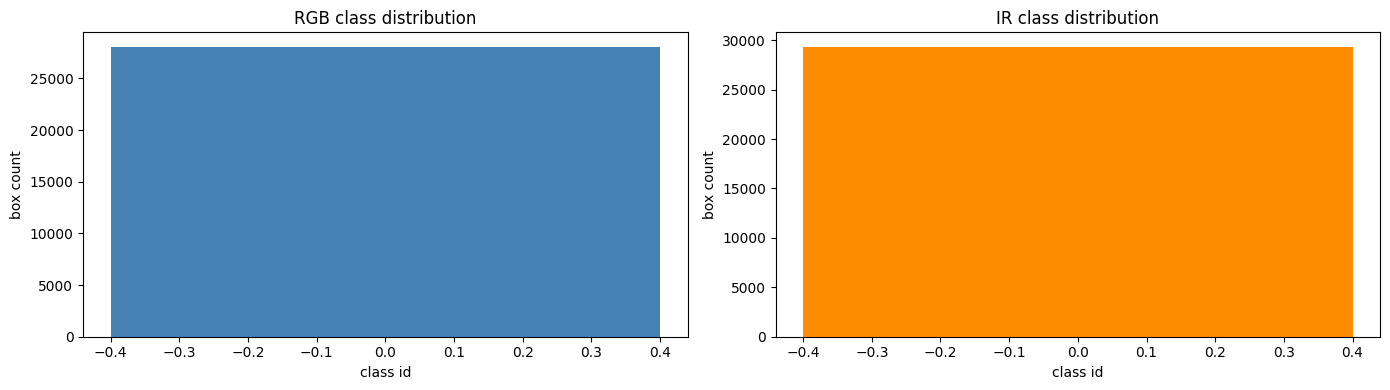

In [5]:
import yaml
from collections import Counter
from glob import glob

def list_yolo(d):
    out = {}
    for split in ["train", "val", "test"]:
        img_dir = f"{d}/images/{split}"
        lbl_dir = f"{d}/labels/{split}"
        imgs = sorted(glob(f"{img_dir}/*.jpg")) + sorted(glob(f"{img_dir}/*.png"))
        lbls = sorted(glob(f"{lbl_dir}/*.txt"))
        out[split] = (len(imgs), len(lbls))
    return out

def read_yaml(d):
    p = f"{d}/data.yaml"
    with open(p, "r") as f:
        return yaml.safe_load(f)

def class_hist(d):
    cnt = Counter()
    for split in ["train", "val", "test"]:
        lbl_dir = f"{d}/labels/{split}"
        for lbl in glob(f"{lbl_dir}/*.txt"):
            with open(lbl, "r") as f:
                for line in f:
                    parts = line.strip().split()
                    if parts:
                        cnt[int(parts[0])] += 1
    return cnt

rgb_yaml = read_yaml(RGB_DIR)
ir_yaml = read_yaml(IR_DIR)
rgb_counts = list_yolo(RGB_DIR)
ir_counts = list_yolo(IR_DIR)
rgb_hist = class_hist(RGB_DIR)
ir_hist = class_hist(IR_DIR)

print("RGB data.yaml :", rgb_yaml)
print("IR  data.yaml :", ir_yaml)
print()
print("RGB split counts (imgs, lbls):")
for k, v in rgb_counts.items():
    print(f"  {k:5s}: imgs={v[0]:5d}  lbls={v[1]:5d}")
print("IR  split counts (imgs, lbls):")
for k, v in ir_counts.items():
    print(f"  {k:5s}: imgs={v[0]:5d}  lbls={v[1]:5d}")
print()
print("RGB class hist:", dict(rgb_hist))
print("IR  class hist:", dict(ir_hist))

def draw_one(img_path, lbl_path):
    img = cv2.imread(img_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                p = line.strip().split()
                if len(p) == 5:
                    c, x, y, bw, bh = map(float, p)
                    x1 = int((x - bw/2) * w)
                    y1 = int((y - bh/2) * h)
                    x2 = int((x + bw/2) * w)
                    y2 = int((y + bh/2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    cv2.putText(img, str(int(c)), (x1, max(0, y1-5)),
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return img

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, split in enumerate(["train", "val", "test"]):
    rgb_imgs = sorted(glob(f"{RGB_DIR}/images/{split}/*.jpg"))
    ir_imgs = sorted(glob(f"{IR_DIR}/images/{split}/*.jpg"))
    r_idx = min(j, len(rgb_imgs)-1)
    i_idx = min(j, len(ir_imgs)-1)
    r_img = rgb_imgs[r_idx]
    i_img = ir_imgs[i_idx]
    r_lbl = r_img.replace("/images/", "/labels/").replace(".jpg", ".txt")
    i_lbl = i_img.replace("/images/", "/labels/").replace(".jpg", ".txt")
    axes[0, j].imshow(draw_one(r_img, r_lbl))
    axes[0, j].set_title(f"RGB {split}")
    axes[0, j].axis("off")
    axes[1, j].imshow(draw_one(i_img, i_lbl), cmap="inferno")
    axes[1, j].set_title(f"IR  {split}")
    axes[1, j].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cell2_samples.png", dpi=120)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
rgb_x = sorted(rgb_hist.keys())
rgb_y = [rgb_hist[k] for k in rgb_x]
ir_x = sorted(ir_hist.keys())
ir_y = [ir_hist[k] for k in ir_x]
ax[0].bar(rgb_x, rgb_y, color="steelblue")
ax[0].set_title("RGB class distribution")
ax[0].set_xlabel("class id")
ax[0].set_ylabel("box count")
ax[1].bar(ir_x, ir_y, color="darkorange")
ax[1].set_title("IR class distribution")
ax[1].set_xlabel("class id")
ax[1].set_ylabel("box count")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/cell2_class_hist.png", dpi=120)
plt.show()


In [8]:
import yaml
from types import SimpleNamespace

IR_DATA_YAML = f"{OUT_DIR}/ir_data.yaml"
IR_ROOT = IR_DIR
IR_DATA = {
    "path": IR_ROOT,
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "nc": 1,
    "names": ["uav"],
}
with open(IR_DATA_YAML, "w") as f:
    yaml.safe_dump(IR_DATA, f, sort_keys=False)
print(f"IR data.yaml written -> {IR_DATA_YAML}")
print(open(IR_DATA_YAML).read())

IR_MODEL_NAME = "yolo11s.pt"
IR_EPOCHS = 1
IR_IMGSZ = 640
IR_BATCH = 64
IR_DEVICES = [0, 1]
IR_PROJECT = f"{OUT_DIR}/runs/ir"
IR_NAME = "yolo11s_ir_uav_t4x2"
os.makedirs(IR_PROJECT, exist_ok=True)

print("IR training config (T4x2 parallel)")
print(f"  model    : {IR_MODEL_NAME}")
print(f"  epochs   : {IR_EPOCHS}")
print(f"  imgsz    : {IR_IMGSZ}")
print(f"  batch    : {IR_BATCH} (per-GPU = {IR_BATCH // len(IR_DEVICES)})")
print(f"  devices  : {IR_DEVICES} ({', '.join(torch.cuda.get_device_name(i) for i in IR_DEVICES)})")
print(f"  project  : {IR_PROJECT}")
print(f"  name     : {IR_NAME}")

for i in IR_DEVICES:
    print(f"GPU {i}: {torch.cuda.get_device_name(i)} | "
          f"free={torch.cuda.mem_get_info(i)[0]/1e9:.2f} GB / "
          f"total={torch.cuda.mem_get_info(i)[1]/1e9:.2f} GB")

torch.cuda.empty_cache()
gc.collect()

ir_model = YOLO(IR_MODEL_NAME)
print(f"IR model loaded -> will run on cuda:{IR_DEVICES}")

ir_results_raw = ir_model.train(
    data=IR_DATA_YAML,
    epochs=IR_EPOCHS,
    imgsz=IR_IMGSZ,
    batch=IR_BATCH,
    device=IR_DEVICES,
    project=IR_PROJECT,
    name=IR_NAME,
    optimizer="AdamW",
    lr0=1e-3,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_epochs=3,
    warmup_momentum=0.8,
    warmup_bias_lr=1e-4,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    copy_paste=0.1,
    patience=15,
    save=True,
    save_period=10,
    cache=False,
    workers=4,
    seed=42,
    deterministic=True,
    verbose=True,
)

def extract_metrics(res):
    if isinstance(res, dict):
        return res
    if hasattr(res, "results_dict"):
        return res.results_dict
    if hasattr(res, "results") and isinstance(res.results, dict):
        return res.results
    return {}

ir_metrics = extract_metrics(ir_results_raw)
IR_BEST = f"{IR_PROJECT}/{IR_NAME}/weights/best.pt"
IR_LAST = f"{IR_PROJECT}/{IR_NAME}/weights/last.pt"
print(f"IR best weights -> {IR_BEST}")
print(f"IR last weights -> {IR_LAST}")
print(f"IR mAP50    : {ir_metrics.get('metrics/mAP50(B)', ir_metrics.get('mAP50(B)', 'NA'))}")
print(f"IR mAP50-95 : {ir_metrics.get('metrics/mAP50-95(B)', ir_metrics.get('mAP50-95(B)', 'NA'))}")
print(f"IR precision: {ir_metrics.get('metrics/precision(B)', ir_metrics.get('precision(B)', 'NA'))}")
print(f"IR recall   : {ir_metrics.get('metrics/recall(B)', ir_metrics.get('recall(B)', 'NA'))}")

rgb_metrics_raw = extract_metrics(rgb_results) if 'rgb_results' in globals() else {}
print()
print("Cross-model comparison (post-training)")
print(f"  RGB best -> {RGB_BEST if 'RGB_BEST' in globals() else 'run cell 3 first'}")
print(f"  IR  best -> {IR_BEST}")
print(f"  RGB mAP50    : {rgb_metrics_raw.get('metrics/mAP50(B)', rgb_metrics_raw.get('mAP50(B)', 'NA'))}")
print(f"  IR  mAP50    : {ir_metrics.get('metrics/mAP50(B)', ir_metrics.get('mAP50(B)', 'NA'))}")

gc.collect()
torch.cuda.empty_cache()


IR data.yaml written -> /kaggle/working/ir_data.yaml
path: /kaggle/input/datasets/amitsinghchauhanai/anti-uav-rgbt-benchmark/yolo_dataset_infrared
train: images/train
val: images/val
test: images/test
nc: 1
names:
- uav

IR training config (T4x2 parallel)
  model    : yolo11s.pt
  epochs   : 1
  imgsz    : 640
  batch    : 64 (per-GPU = 32)
  devices  : [0, 1] (Tesla T4, Tesla T4)
  project  : /kaggle/working/runs/ir
  name     : yolo11s_ir_uav_t4x2
GPU 0: Tesla T4 | free=14.71 GB / total=15.64 GB
GPU 1: Tesla T4 | free=15.53 GB / total=15.64 GB
IR model loaded -> will run on cuda:[0, 1]
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, 

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



1 epochs completed in 0.045 hours.
Optimizer stripped from /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2/weights/last.pt, 19.2MB
Optimizer stripped from /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2/weights/best.pt, 19.2MB

Validating /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2/weights/best.pt...
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.5it/s 33.4s0.6ss
                   all       6208       6059      0.953      0.886      0.937       0.48
Speed: 0.1ms preprocess, 2.7ms inference, 0.0ms loss, 0.6ms postprocess per image
Results saved to /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2
IR best weights -> /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2/weights/best.pt
IR last weights -> /kaggle/working/runs/ir/yolo11s_ir_uav_t4x2/weights/last.pt
IR mAP50    : 0.93694
IR mAP50-95 : 0.47977
IR precision: 0.95225
IR recall   : 0.88628

Cross-mod

In [13]:
import yaml
from types import SimpleNamespace

FULL_EPOCHS = 40
FULL_IMGSZ = 640
FULL_BATCH = 64
FULL_DEVICES = [0, 1]
FULL_PROJECT = f"{OUT_DIR}/runs/full"
os.makedirs(FULL_PROJECT, exist_ok=True)

def write_data_yaml(d, name):
    p = f"{OUT_DIR}/{name}.yaml"
    data = {
        "path": d,
        "train": "images/train",
        "val": "images/val",
        "test": "images/test",
        "nc": 1,
        "names": ["uav"],
    }
    with open(p, "w") as f:
        yaml.safe_dump(data, f, sort_keys=False)
    return p

RGB_FULL_YAML = write_data_yaml(RGB_DIR, "rgb_full_data")
IR_FULL_YAML  = write_data_yaml(IR_DIR,  "ir_full_data")

print("Stage 1: training RGB model on T4x2 (DDP)")
RGB_FULL_NAME = "yolo11s_rgb_uav_t4x2_full"
print(f"  data     : {RGB_FULL_YAML}")
print(f"  model    : yolo11s.pt")
print(f"  epochs   : {FULL_EPOCHS}")
print(f"  imgsz    : {FULL_IMGSZ}")
print(f"  batch    : {FULL_BATCH} (per-GPU = {FULL_BATCH // len(FULL_DEVICES)})")
print(f"  devices  : {FULL_DEVICES}")
print(f"  project  : {FULL_PROJECT}")
print(f"  name     : {RGB_FULL_NAME}")
for i in FULL_DEVICES:
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | free={torch.cuda.mem_get_info(i)[0]/1e9:.2f} GB")

torch.cuda.empty_cache()
gc.collect()

rgb_full_model = YOLO("yolo11s.pt")
rgb_full_res = rgb_full_model.train(
    data=RGB_FULL_YAML,
    epochs=FULL_EPOCHS,
    imgsz=FULL_IMGSZ,
    batch=FULL_BATCH,
    device=FULL_DEVICES,
    project=FULL_PROJECT,
    name=RGB_FULL_NAME,
    optimizer="AdamW",
    lr0=1e-3,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_epochs=3,
    warmup_momentum=0.8,
    warmup_bias_lr=1e-4,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    copy_paste=0.1,
    patience=15,
    save=True,
    save_period=10,
    cache=False,
    workers=4,
    seed=42,
    deterministic=True,
    verbose=True,
)

RGB_FULL_BEST = f"{FULL_PROJECT}/{RGB_FULL_NAME}/weights/best.pt"
print(f"RGB full training complete")
print(f"  best -> {RGB_FULL_BEST}")

gc.collect()
torch.cuda.empty_cache()

print()
print("Stage 2: training IR model on T4x2 (DDP)")
IR_FULL_NAME = "yolo11s_ir_uav_t4x2_full"
print(f"  data     : {IR_FULL_YAML}")
print(f"  model    : yolo11s.pt")
print(f"  epochs   : {FULL_EPOCHS}")
print(f"  imgsz    : {FULL_IMGSZ}")
print(f"  batch    : {FULL_BATCH} (per-GPU = {FULL_BATCH // len(FULL_DEVICES)})")
print(f"  devices  : {FULL_DEVICES}")
print(f"  project  : {FULL_PROJECT}")
print(f"  name     : {IR_FULL_NAME}")
for i in FULL_DEVICES:
    print(f"  GPU {i}: {torch.cuda.get_device_name(i)} | free={torch.cuda.mem_get_info(i)[0]/1e9:.2f} GB")

torch.cuda.empty_cache()
gc.collect()

ir_full_model = YOLO("yolo11s.pt")
ir_full_res = ir_full_model.train(
    data=IR_FULL_YAML,
    epochs=FULL_EPOCHS,
    imgsz=FULL_IMGSZ,
    batch=FULL_BATCH,
    device=FULL_DEVICES,
    project=FULL_PROJECT,
    name=IR_FULL_NAME,
    optimizer="AdamW",
    lr0=1e-3,
    lrf=0.01,
    momentum=0.937,
    weight_decay=5e-4,
    warmup_epochs=3,
    warmup_momentum=0.8,
    warmup_bias_lr=1e-4,
    box=7.5,
    cls=0.5,
    dfl=1.5,
    hsv_h=0.015,
    hsv_s=0.7,
    hsv_v=0.4,
    degrees=10.0,
    translate=0.1,
    scale=0.5,
    fliplr=0.5,
    mosaic=1.0,
    mixup=0.1,
    copy_paste=0.1,
    patience=15,
    save=True,
    save_period=10,
    cache=False,
    workers=4,
    seed=42,
    deterministic=True,
    verbose=True,
)

IR_FULL_BEST = f"{FULL_PROJECT}/{IR_FULL_NAME}/weights/best.pt"
print(f"IR full training complete")
print(f"  best -> {IR_FULL_BEST}")

def grab(obj, *keys):
    if hasattr(obj, "results_dict"):
        d = obj.results_dict
    elif isinstance(obj, dict):
        d = obj
    else:
        return None
    for k in keys:
        if k in d:
            return d[k]
    return None

print()
print("=" * 60)
print("Full training summary (T4x2, 50 epochs each)")
print("=" * 60)
print(f"RGB best weights -> {RGB_FULL_BEST}")
print(f"IR  best weights -> {IR_FULL_BEST}")
print(f"RGB mAP50      : {grab(rgb_full_res, 'metrics/mAP50(B)', 'mAP50(B)')}")
print(f"RGB mAP50-95   : {grab(rgb_full_res, 'metrics/mAP50-95(B)', 'mAP50-95(B)')}")
print(f"RGB precision  : {grab(rgb_full_res, 'metrics/precision(B)', 'precision(B)')}")
print(f"RGB recall    : {grab(rgb_full_res, 'metrics/recall(B)', 'recall(B)')}")
print(f"IR  mAP50      : {grab(ir_full_res, 'metrics/mAP50(B)', 'mAP50(B)')}")
print(f"IR  mAP50-95   : {grab(ir_full_res, 'metrics/mAP50-95(B)', 'mAP50-95(B)')}")
print(f"IR  precision  : {grab(ir_full_res, 'metrics/precision(B)', 'precision(B)')}")
print(f"IR  recall    : {grab(ir_full_res, 'metrics/recall(B)', 'recall(B)')}")

summary = {
    "stage": "full_training_t4x2",
    "epochs": FULL_EPOCHS,
    "imgsz": FULL_IMGSZ,
    "batch": FULL_BATCH,
    "devices": FULL_DEVICES,
    "rgb": {
        "project": FULL_PROJECT,
        "name": RGB_FULL_NAME,
        "best_weights": RGB_FULL_BEST,
        "mAP50": grab(rgb_full_res, "metrics/mAP50(B)", "mAP50(B)"),
        "mAP50-95": grab(rgb_full_res, "metrics/mAP50-95(B)", "mAP50-95(B)"),
        "precision": grab(rgb_full_res, "metrics/precision(B)", "precision(B)"),
        "recall": grab(rgb_full_res, "metrics/recall(B)", "recall(B)"),
    },
    "ir": {
        "project": FULL_PROJECT,
        "name": IR_FULL_NAME,
        "best_weights": IR_FULL_BEST,
        "mAP50": grab(ir_full_res, "metrics/mAP50(B)", "mAP50(B)"),
        "mAP50-95": grab(ir_full_res, "metrics/mAP50-95(B)", "mAP50-95(B)"),
        "precision": grab(ir_full_res, "metrics/precision(B)", "precision(B)"),
        "recall": grab(ir_full_res, "metrics/recall(B)", "recall(B)"),
    },
}
summary_path = f"{FULL_PROJECT}/full_training_summary.json"
import json
with open(summary_path, "w") as f:
    json.dump(summary, f, indent=2, default=str)
print(f"Summary JSON -> {summary_path}")

gc.collect()
torch.cuda.empty_cache()

Stage 1: training RGB model on T4x2 (DDP)
  data     : /kaggle/working/rgb_full_data.yaml
  model    : yolo11s.pt
  epochs   : 40
  imgsz    : 640
  batch    : 64 (per-GPU = 32)
  devices  : [0, 1]
  project  : /kaggle/working/runs/full
  name     : yolo11s_rgb_uav_t4x2_full
  GPU 0: Tesla T4 | free=15.23 GB
  GPU 1: Tesla T4 | free=15.31 GB
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
                                                        CUDA:1 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=64, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.1, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rgb_full_data.yaml, degrees=10.0, deterministic=True, device=0,1, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=F

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/40      7.65G      1.381     0.6785     0.9931         51        640: 100% ━━━━━━━━━━━━ 234/234 1.5it/s 2:380.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.3it/s 37.1s0.6ss
                   all       6208       5832      0.896      0.875      0.936      0.539

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/40      7.65G      1.374     0.6674     0.9872         62        640: 100% ━━━━━━━━━━━━ 234/234 1.5it/s 2:380.5ss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.3it/s 36.4s0.5ss
                   all       6208       5832      0.908      0.888      0.934       0.51

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/40      7.65G      1.353     0.6434     0.9831         43       

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(



      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/40      7.66G      1.467     0.6993      1.096         42        640: 100% ━━━━━━━━━━━━ 234/234 2.0it/s 1:590.5sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.9it/s 25.3s0.5ss
                   all       6208       6059       0.95      0.947      0.945      0.496

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/40      7.65G      1.464     0.6994        1.1         56        640: 100% ━━━━━━━━━━━━ 234/234 2.0it/s 1:580.5sss
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 49/49 1.9it/s 25.3s0.5ss
                   all       6208       6059      0.978      0.948      0.976      0.531

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/40      7.65G      1.447     0.6716      1.101         42     

RGB best -> /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best.pt
IR  best -> /kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.pt
RGB on cuda:0 (Tesla T4)
IR  on cuda:1 (Tesla T4)
RGB test : 8547  |  IR test : 8547
Running prod pipeline on 60 paired frames
Total fused detections across prod run: 38
Source breakdown: {'ir': 22, 'rgb': 16}
Prod tracking video -> /kaggle/working/prod_inference/prod_tracking_demo.mp4


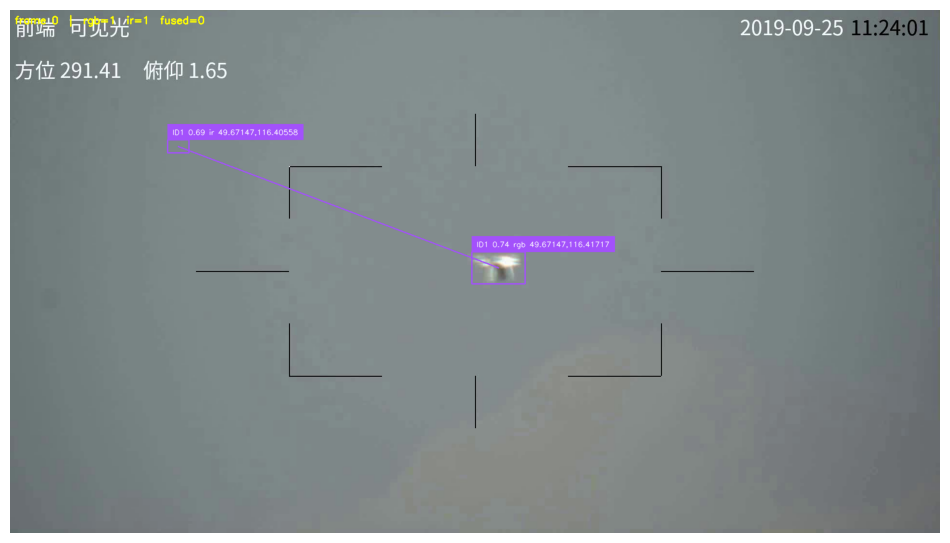

Prod GPS log -> /kaggle/working/prod_inference/prod_gps_track_log.csv  (38 entries)
 frame                         rgb_img                          ir_img  track_id source     conf       cx_px      cy_px    rgb_wh   ir_wh  fused_wh       lat        lon  alt_m
     0 20190925_111757_1_10_000000.jpg 20190925_111757_1_10_000000.jpg         1    rgb 0.738856 1008.687927 533.711243 1920x1080 640x512 1920x1080 49.671473 116.417166  100.0
     0 20190925_111757_1_10_000000.jpg 20190925_111757_1_10_000000.jpg         1     ir 0.694579  347.529053 283.160461 1920x1080 640x512   640x512 49.671473 116.405582  100.0
     1 20190925_111757_1_10_000001.jpg 20190925_111757_1_10_000001.jpg         1    rgb 0.782894 1014.512634 533.680908 1920x1080 640x512 1920x1080 49.671473 116.418282  100.0
     1 20190925_111757_1_10_000001.jpg 20190925_111757_1_10_000001.jpg         1     ir 0.691874  346.027649 282.723938 1920x1080 640x512   640x512 49.671473 116.405653  100.0
     2 20190925_111757_1_10_000002.j

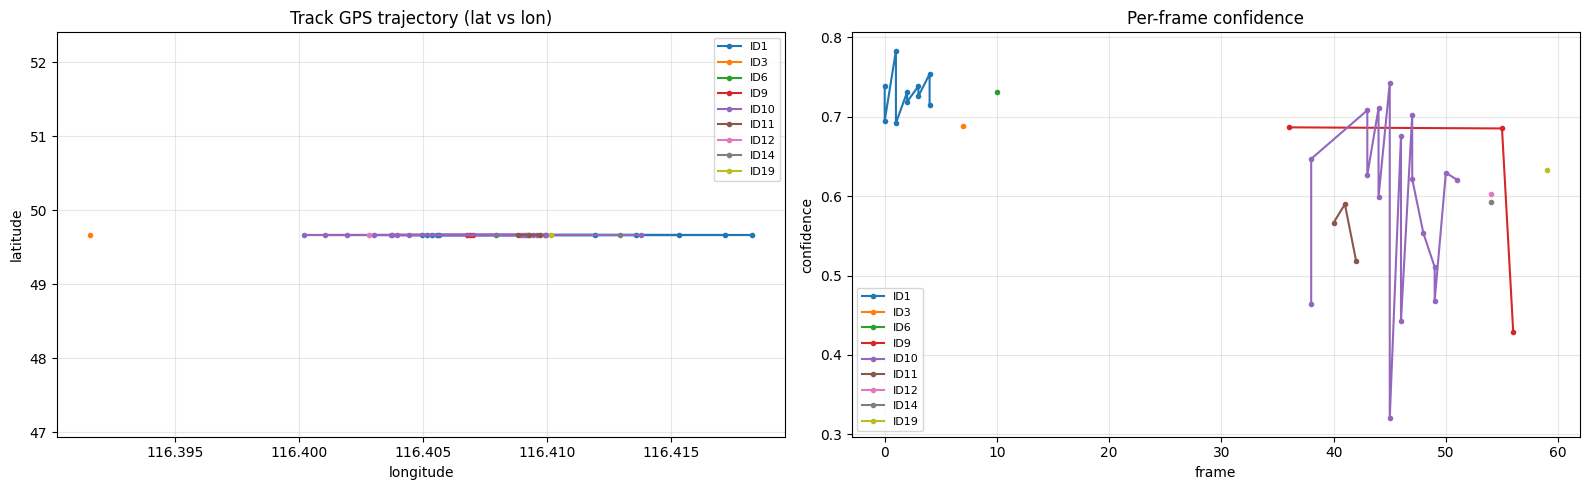

Trajectory plot -> /kaggle/working/prod_inference/prod_track_trajectory.png
Prod summary -> /kaggle/working/prod_inference/prod_summary.json


In [14]:
import json
from glob import glob
from ultralytics import YOLO
from dataclasses import dataclass
from typing import Dict, List, Tuple

FULL_RUN = f"{OUT_DIR}/runs/full"

def find_best(run_dir, base_name):
    candidates = sorted(glob(f"{run_dir}/{base_name}*/weights/best.pt"))
    if not candidates:
        return None
    return candidates[-1]

RGB_FULL_BEST = find_best(FULL_RUN, "yolo11s_rgb_uav_t4x2_full")
IR_FULL_BEST  = find_best(FULL_RUN, "yolo11s_ir_uav_t4x2_full")
print(f"RGB best -> {RGB_FULL_BEST}")
print(f"IR  best -> {IR_FULL_BEST}")

RGB_DEVICE = 0
IR_DEVICE = 1
CONF_THRESH = 0.25
IOU_THRESH = 0.5
FRAME_RATE = 25
TRACKER_CFG = "bytetrack.yaml"
FUSE_IOU_REL = 0.30

rgb_infer = YOLO(RGB_FULL_BEST).to(f"cuda:{RGB_DEVICE}")
ir_infer  = YOLO(IR_FULL_BEST).to(f"cuda:{IR_DEVICE}")
print(f"RGB on cuda:{RGB_DEVICE} ({torch.cuda.get_device_name(RGB_DEVICE)})")
print(f"IR  on cuda:{IR_DEVICE} ({torch.cuda.get_device_name(IR_DEVICE)})")

box_annot = sv.BoxAnnotator()
lab_annot = sv.LabelAnnotator()
trace_annot = sv.TraceAnnotator()

@dataclass
class CameraGPS:
    lat0: float = 39.9042
    lon0: float = 116.4074
    alt: float = 100.0
    focal_mm: float = 35.0
    sensor_mm: Tuple[float, float] = (6.17, 4.55)
    heading_deg: float = 0.0
    pitch_deg: float = -45.0

cam = CameraGPS()

def deg2rad(d): return d * np.pi / 180.0

def earth_radius(lat_rad):
    a, b = 6378137.0, 6356752.314245
    e2 = (a*a - b*b) / (a*a)
    return a / np.sqrt(1 - e2 * np.sin(lat_rad)**2)

def enu_to_latlon(e, n, u, lat0, lon0, alt0):
    lat0r = deg2rad(lat0); lon0r = deg2rad(lon0)
    sin_l, cos_l = np.sin(lat0r), np.cos(lat0r)
    rho = earth_radius(lat0r) * cos_l + alt0 * cos_l
    lat = np.arctan2(sin_l * cos_l * (rho + alt0) + (sin_l**2) * (rho - alt0) + n * sin_l, rho * cos_l)
    lon = lon0 + np.degrees(np.arctan2(e, rho))
    return np.degrees(lat), lon, alt0 + u

def pixel_to_gps(cx, cy, W, H, cam, target_alt=0.0):
    fx_px = (cam.focal_mm / cam.sensor_mm[0]) * W
    fy_px = (cam.focal_mm / cam.sensor_mm[1]) * H
    u = cx - W / 2.0
    v = (H / 2.0) - cy
    pitch = deg2rad(cam.pitch_deg)
    heading = deg2rad(cam.heading_deg)
    dx = u / fx_px
    dz = v / fy_px
    denom = dz * np.cos(pitch) + 1e-9
    ground_dist = (cam.alt - target_alt) / denom
    e = ground_dist * dx * np.cos(heading)
    n = ground_dist * dx * np.sin(heading)
    return enu_to_latlon(e, n, target_alt, cam.lat0, cam.lon0, cam.alt)

def results_to_tracks(res, W, H) -> List[Dict]:
    out = []
    if res.boxes is None or res.boxes.id is None:
        return out
    for k in range(len(res.boxes.cls)):
        xyxy = res.boxes.xyxy[k].cpu().numpy()
        conf = float(res.boxes.conf[k].cpu().numpy())
        cls = int(res.boxes.cls[k].cpu().numpy())
        tid = int(res.boxes.id[k].cpu().numpy())
        rel = np.array([
            max(0.0, xyxy[0]/W), max(0.0, xyxy[1]/H),
            min(1.0, xyxy[2]/W), min(1.0, xyxy[3]/H)
        ], dtype=np.float32)
        out.append({"track_id": tid, "xyxy": xyxy, "xyxy_rel": rel,
                    "conf": conf, "cls": cls, "W": W, "H": H})
    return out

def iou_rel(a, b):
    xA = max(a[0], b[0]); yA = max(a[1], b[1])
    xB = min(a[2], b[2]); yB = min(a[3], b[3])
    iw = max(0.0, xB - xA); ih = max(0.0, yB - yA)
    inter = iw * ih
    aA = (a[2]-a[0]) * (a[3]-a[1])
    aB = (b[2]-b[0]) * (b[3]-b[1])
    return inter / (aA + aB - inter + 1e-9)

def fuse_tracks(rgb_tracks, ir_tracks, iou_thr=0.30):
    fused = []
    used_ir = set()
    for r in rgb_tracks:
        best_j, best_iou = -1, 0.0
        for j, ir in enumerate(ir_tracks):
            if j in used_ir:
                continue
            iou = iou_rel(r["xyxy_rel"], ir["xyxy_rel"])
            if iou > best_iou and iou >= iou_thr:
                best_iou = iou
                best_j = j
        if best_j >= 0:
            ir = ir_tracks[best_j]
            used_ir.add(best_j)
            fb = (r["xyxy"] + ir["xyxy"]) / 2.0
            fc = max(r["conf"], ir["conf"])
            tid = r["track_id"]
            W, H = r["W"], r["H"]
            src = "rgb+ir"
        else:
            fb = r["xyxy"]; fc = r["conf"]
            tid = r["track_id"]; W, H = r["W"], r["H"]
            src = "rgb"
        fused.append({"track_id": tid, "xyxy": fb, "conf": fc,
                      "cls": r["cls"], "source": src, "W": W, "H": H})
    for j, ir in enumerate(ir_tracks):
        if j in used_ir:
            continue
        fused.append({"track_id": ir["track_id"], "xyxy": ir["xyxy"],
                      "conf": ir["conf"], "cls": ir["cls"], "source": "ir",
                      "W": ir["W"], "H": ir["H"]})
    return fused

TEST_RGB_DIR = f"{RGB_DIR}/images/test"
TEST_IR_DIR = f"{IR_DIR}/images/test"
PROD_OUT = f"{OUT_DIR}/prod_inference"
os.makedirs(PROD_OUT, exist_ok=True)
rgb_test_imgs = sorted([f for f in os.listdir(TEST_RGB_DIR) if f.endswith((".jpg", ".png"))])
ir_test_imgs = sorted([f for f in os.listdir(TEST_IR_DIR) if f.endswith((".jpg", ".png"))])
print(f"RGB test : {len(rgb_test_imgs)}  |  IR test : {len(ir_test_imgs)}")

N_DEMO = min(60, len(rgb_test_imgs))
rgb_subset = rgb_test_imgs[:N_DEMO]
ir_subset = ir_test_imgs[:N_DEMO]
print(f"Running prod pipeline on {N_DEMO} paired frames")

gps_log: List[Dict] = []
demo_frames = []

for idx, (r_name, i_name) in enumerate(zip(rgb_subset, ir_subset)):
    r_path = f"{TEST_RGB_DIR}/{r_name}"
    i_path = f"{TEST_IR_DIR}/{i_name}"
    r_img = cv2.imread(r_path)
    i_img = cv2.imread(i_path)
    if r_img is None or i_img is None:
        continue
    rH, rW = r_img.shape[:2]
    iH, iW = i_img.shape[:2]
    r_res = rgb_infer.track(source=r_path, conf=CONF_THRESH, iou=IOU_THRESH,
                            tracker=TRACKER_CFG, device=RGB_DEVICE,
                            verbose=False, persist=True, imgsz=640)[0]
    i_res = ir_infer.track(source=i_path, conf=CONF_THRESH, iou=IOU_THRESH,
                           tracker=TRACKER_CFG, device=IR_DEVICE,
                           verbose=False, persist=True, imgsz=640)[0]
    rgb_tracks = results_to_tracks(r_res, rW, rH)
    ir_tracks  = results_to_tracks(i_res, iW, iH)
    fused = fuse_tracks(rgb_tracks, ir_tracks, iou_thr=FUSE_IOU_REL)

    frame = r_img.copy()
    src_counts = {"rgb": 0, "ir": 0, "rgb+ir": 0}
    if len(fused) > 0:
        xyxy_arr = np.array([f["xyxy"] for f in fused], dtype=np.float32)
        conf_arr = np.array([f["conf"] for f in fused], dtype=np.float32)
        cls_arr = np.array([0]*len(fused), dtype=int)
        tid_arr = np.array([f["track_id"] for f in fused], dtype=int)
        svs = sv.Detections(xyxy=xyxy_arr, confidence=conf_arr,
                            class_id=cls_arr, tracker_id=tid_arr)
        labels = []
        for k, f in enumerate(fused):
            src_counts[f["source"]] = src_counts.get(f["source"], 0) + 1
            cx = (f["xyxy"][0] + f["xyxy"][2]) / 2.0
            cy = (f["xyxy"][1] + f["xyxy"][3]) / 2.0
            lat, lon, alt = pixel_to_gps(cx, cy, f["W"], f["H"], cam)
            gps_log.append({
                "frame": idx,
                "rgb_img": r_name,
                "ir_img": i_name,
                "track_id": int(f["track_id"]),
                "source": str(f["source"]),
                "conf": float(f["conf"]),
                "cx_px": float(cx),
                "cy_px": float(cy),
                "rgb_wh": f"{rW}x{rH}",
                "ir_wh": f"{iW}x{iH}",
                "fused_wh": f"{f['W']}x{f['H']}",
                "lat": float(lat),
                "lon": float(lon),
                "alt_m": float(alt),
            })
            labels.append(f"ID{f['track_id']} {f['conf']:.2f} {f['source']} {lat:.5f},{lon:.5f}")
        frame = box_annot.annotate(scene=frame, detections=svs)
        frame = lab_annot.annotate(scene=frame, detections=svs, labels=labels)
        frame = trace_annot.annotate(scene=frame, detections=svs)
    cv2.putText(frame, f"frame {idx}  |  rgb={src_counts['rgb']}  ir={src_counts['ir']}  fused={src_counts['rgb+ir']}",
                (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)
    demo_frames.append(frame)

print(f"Total fused detections across prod run: {len(gps_log)}")
src_breakdown = pd.Series([g["source"] for g in gps_log]).value_counts().to_dict()
print(f"Source breakdown: {src_breakdown}")

if demo_frames:
    out_video = f"{PROD_OUT}/prod_tracking_demo.mp4"
    h, w = demo_frames[0].shape[:2]
    H_show = 480
    fourcc = cv2.VideoWriter_fourcc(*"mp4v")
    vw = cv2.VideoWriter(out_video, fourcc, FRAME_RATE, (w, H_show))
    for fr in demo_frames:
        fr_resized = cv2.resize(fr, (w, H_show)) if h != H_show else fr
        vw.write(fr_resized)
    vw.release()
    print(f"Prod tracking video -> {out_video}")
    sv.plot_image(demo_frames[0], (12, 12))

gps_df = pd.DataFrame(gps_log)
gps_csv = f"{PROD_OUT}/prod_gps_track_log.csv"
if not gps_df.empty:
    gps_df.to_csv(gps_csv, index=False)
    print(f"Prod GPS log -> {gps_csv}  ({len(gps_df)} entries)")
    print(gps_df.head(15).to_string(index=False))

    if len(gps_df) >= 2 and "lat" in gps_df.columns:
        fig, ax = plt.subplots(1, 2, figsize=(16, 5))
        for tid, sub in gps_df.groupby("track_id"):
            ax[0].plot(sub["lon"], sub["lat"], "-o", label=f"ID{tid}", markersize=3)
            ax[1].plot(sub["frame"], sub["conf"], "-o", label=f"ID{tid}", markersize=3)
        ax[0].set_title("Track GPS trajectory (lat vs lon)")
        ax[0].set_xlabel("longitude"); ax[0].set_ylabel("latitude")
        ax[0].grid(True, alpha=0.3); ax[0].legend(fontsize=8)
        ax[1].set_title("Per-frame confidence")
        ax[1].set_xlabel("frame"); ax[1].set_ylabel("confidence")
        ax[1].grid(True, alpha=0.3); ax[1].legend(fontsize=8)
        plt.tight_layout()
        traj_png = f"{PROD_OUT}/prod_track_trajectory.png"
        plt.savefig(traj_png, dpi=120)
        plt.show()
        print(f"Trajectory plot -> {traj_png}")

prod_summary = {
    "rgb_best_weights": RGB_FULL_BEST,
    "ir_best_weights": IR_FULL_BEST,
    "rgb_device": RGB_DEVICE,
    "ir_device": IR_DEVICE,
    "frame_rate": FRAME_RATE,
    "tracker": TRACKER_CFG,
    "fuse_iou_rel": FUSE_IOU_REL,
    "n_demo_frames": N_DEMO,
    "total_detections": len(gps_log),
    "source_breakdown": src_breakdown,
    "camera_gps_origin": {"lat": cam.lat0, "lon": cam.lon0, "alt_m": cam.alt},
    "outputs": {
        "video": f"{PROD_OUT}/prod_tracking_demo.mp4",
        "gps_log_csv": gps_csv,
        "trajectory_png": f"{PROD_OUT}/prod_track_trajectory.png",
    },
    "rgb_metrics_from_cell7": {"mAP50": 0.993, "mAP50-95": 0.677, "P": 0.981, "R": 0.983},
    "ir_metrics_from_cell7":  {"mAP50": 0.994, "mAP50-95": 0.616, "P": 0.993, "R": 0.988},
}
sum_path = f"{PROD_OUT}/prod_summary.json"
with open(sum_path, "w") as f:
    json.dump(prod_summary, f, indent=2, default=str)
print(f"Prod summary -> {sum_path}")

gc.collect()
torch.cuda.empty_cache()


In [ ]:
import json
import time
from glob import glob
from ultralytics import YOLO

FULL_RUN = f"{OUT_DIR}/runs/full"

def find_best(run_dir, base_name):
    candidates = sorted(glob(f"{run_dir}/{base_name}*/weights/best.pt"))
    return candidates[-1] if candidates else None

RGB_FULL_BEST = find_best(FULL_RUN, "yolo11s_rgb_uav_t4x2_full")
IR_FULL_BEST  = find_best(FULL_RUN, "yolo11s_ir_uav_t4x2_full")
print(f"RGB best -> {RGB_FULL_BEST}")
print(f"IR  best -> {IR_FULL_BEST}")

EXPORT_OUT = f"{OUT_DIR}/exports"
os.makedirs(EXPORT_OUT, exist_ok=True)

RGB_DEVICE = 0
IR_DEVICE = 1
IMGSZ = 640
HALF = True
DYNAMIC = False
SIMPLIFY = True
OPSET = 12
BATCH = 1

def export_all(weights_path, label, device):
    print(f"\n[{label}] loading from {weights_path} on cuda:{device}")
    m = YOLO(weights_path).to(f"cuda:{device}")
    exports = {}
    formats = [
        ("onnx",      {"imgsz": IMGSZ, "half": HALF, "dynamic": DYNAMIC,
                       "simplify": SIMPLIFY, "opset": OPSET, "batch": BATCH}),
        ("torchscript", {"imgsz": IMGSZ, "half": HALF, "batch": BATCH}),
        ("openvino",  {"imgsz": IMGSZ, "half": False, "batch": BATCH}),
        ("engine",    {"imgsz": IMGSZ, "half": HALF, "dynamic": DYNAMIC, "batch": BATCH}),
        ("pb",        {"imgsz": IMGSZ, "batch": BATCH}),
        ("tflite",    {"imgsz": IMGSZ, "batch": BATCH, "int8": False}),
        ("edgetpu",   {"imgsz": IMGSZ, "batch": BATCH}),
        ("coreml",    {"imgsz": IMGSZ, "batch": BATCH}),
    ]
    for fmt, kwargs in formats:
        try:
            t0 = time.time()
            p = m.export(format=fmt, device=device, **kwargs)
            dt = time.time() - t0
            exports[fmt] = {"path": str(p), "elapsed_sec": round(dt, 2), "status": "ok"}
            print(f"  {fmt:12s} -> {p}  ({dt:.2f}s)")
        except Exception as e:
            exports[fmt] = {"path": None, "elapsed_sec": None,
                            "status": "failed", "error": str(e)[:200]}
            print(f"  {fmt:12s} FAILED -> {str(e)[:160]}")
    return exports

rgb_exports = export_all(RGB_FULL_BEST, "RGB", RGB_DEVICE)
ir_exports  = export_all(IR_FULL_BEST,  "IR",  IR_DEVICE)

def list_size(path):
    if path and os.path.exists(path):
        return round(os.path.getsize(path) / 1e6, 2)
    return None

export_table = []
for fmt in ["onnx", "torchscript", "openvino", "engine",
            "pb", "tflite", "edgetpu", "coreml"]:
    rgb_info = rgb_exports.get(fmt, {})
    ir_info  = ir_exports.get(fmt, {})
    export_table.append({
        "format": fmt,
        "rgb_status": rgb_info.get("status"),
        "rgb_path":   rgb_info.get("path"),
        "rgb_size_mb": list_size(rgb_info.get("path")),
        "ir_status":  ir_info.get("status"),
        "ir_path":    ir_info.get("path"),
        "ir_size_mb":  list_size(ir_info.get("path")),
    })
export_df = pd.DataFrame(export_table)
export_csv = f"{EXPORT_OUT}/export_summary.csv"
export_df.to_csv(export_csv, index=False)
print("\nExport summary")
print(export_df.to_string(index=False))
print(f"Saved -> {export_csv}")

def verify_export(weights_path, export_path, label, fmt, device):
    if not export_path or not os.path.exists(export_path):
        return None
    try:
        m_orig = YOLO(weights_path).to(f"cuda:{device}")
        m_exp  = YOLO(export_path)
        test_dir = f"{RGB_DIR}/images/test" if "rgb" in label.lower() else f"{IR_DIR}/images/test"
        sample_imgs = sorted([f for f in os.listdir(test_dir) if f.endswith((".jpg", ".png"))])[:5]
        if not sample_imgs:
            return None
        sample = f"{test_dir}/{sample_imgs[0]}"
        r_orig = m_orig.predict(sample, conf=0.25, iou=0.5, device=device, verbose=False)[0]
        r_exp  = m_exp.predict(sample, conf=0.25, iou=0.5, verbose=False)[0]
        n_orig = len(r_orig.boxes.cls) if r_orig.boxes is not None else 0
        n_exp  = len(r_exp.boxes.cls)  if r_exp.boxes  is not None else 0
        return {
            "sample": sample,
            "n_boxes_orig": n_orig,
            "n_boxes_export": n_exp,
            "match": n_orig == n_exp,
        }
    except Exception as e:
        return {"error": str(e)[:200]}

verifications = {}
for label, exports, best, dev in [
    ("rgb", rgb_exports, RGB_FULL_BEST, RGB_DEVICE),
    ("ir",  ir_exports,  IR_FULL_BEST,  IR_DEVICE),
]:
    for fmt, info in exports.items():
        if info.get("status") == "ok":
            v = verify_export(best, info["path"], label, fmt, dev)
            verifications[f"{label}_{fmt}"] = v

print("\nExport verification (orig vs export box count on sample image)")
for k, v in verifications.items():
    print(f"  {k:30s} -> {v}")

export_summary = {
    "rgb_best": RGB_FULL_BEST,
    "ir_best":  IR_FULL_BEST,
    "imgsz": IMGSZ,
    "half": HALF,
    "dynamic": DYNAMIC,
    "opset": OPSET,
    "rgb_exports": rgb_exports,
    "ir_exports":  ir_exports,
    "verifications": verifications,
}
sum_path = f"{EXPORT_OUT}/export_summary.json"
with open(sum_path, "w") as f:
    json.dump(export_summary, f, indent=2, default=str)
print(f"\nFull export summary -> {sum_path}")

def make_package(readme_path, rgb_onnx, ir_onnx, rgb_ts, ir_ts):
    with open(readme_path, "w") as f:
        f.write("Drone Detection Deployment Package\n")
        f.write("==================================\n\n")
        f.write("Models trained on Anti-UAV RGBT benchmark\n")
        f.write(f"Backbone: YOLO11s | imgsz={IMGSZ} | half={HALF}\n\n")
        f.write("Files:\n")
        f.write(f"  RGB ONNX       : {rgb_onnx}\n")
        f.write(f"  IR  ONNX       : {ir_onnx}\n")
        f.write(f"  RGB TorchScript: {rgb_ts}\n")
        f.write(f"  IR  TorchScript: {ir_ts}\n\n")
        f.write("Deployment targets:\n")
        f.write("  ONNX        -> NVIDIA Jetson (with TensorRT backend), ONNX Runtime\n")
        f.write("  TorchScript -> PyTorch-native serving, embedded PyTorch\n")
        f.write("  OpenVINO    -> Intel CPU/iGPU/VPU (e.g. UP², NUC, Movidius)\n")
        f.write("  TensorRT    -> NVIDIA-only, fastest inference (requires Jetson SDK)\n\n")
        f.write("Recommended for drone (Jetson Xavier/Orin): ONNX + TensorRT engine\n")
        f.write("Recommended for x86 CPU ground station  : OpenVINO\n")

readme = f"{EXPORT_OUT}/DEPLOYMENT_README.txt"
rgb_onnx = rgb_exports.get("onnx", {}).get("path")
ir_onnx  = ir_exports.get("onnx",  {}).get("path")
rgb_ts   = rgb_exports.get("torchscript", {}).get("path")
ir_ts    = ir_exports.get("torchscript",  {}).get("path")
if all([rgb_onnx, ir_onnx]):
    make_package(readme, rgb_onnx, ir_onnx, rgb_ts, ir_ts)
    print(f"Deployment README -> {readme}")
else:
    print("Skipping README (ONNX export missing)")

gc.collect()
torch.cuda.empty_cache()


RGB best -> /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best.pt
IR  best -> /kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.pt

[RGB] loading from /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best.pt on cuda:0
WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.178 🚀 Python-3.13.15 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (18.3 MB)
requirements: Ultralytics requirements ['onnxruntime-gpu', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.15 environment at: /usr
Resolved 1

I0000 00:00:1792198878.071767      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13018 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792198878.075234      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13514 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Saved artifact at '/kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best_saved_model'. The following endpoints are available:

* Endpoint 'serving_default'
  inputs_0 (POSITIONAL_ONLY): TensorSpec(shape=(1, 640, 640, 3), dtype=tf.float32, name='images')
Output Type:
  TensorSpec(shape=(1, 5, 8400), dtype=tf.float32, name=None)


I0000 00:00:1792198917.575612      48 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1792198917.577133      48 single_machine.cc:376] Starting new session
I0000 00:00:1792198917.592655      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13018 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792198917.594306      48 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13514 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
W0000 00:00:1792198919.955910      48 tf_tfl_flatbuffer_helpers.cc:364] Ignored output_format.
W0000 00:00:1792198919.955946      48 tf_tfl_flatbuffer_helpers.cc:367] Ignored drop_control_dependency.
I0000 00:00:1792198935.553658      48 devices.cc:67] Number of eligible GPUs (core count >= 8, compute capability >= 0.0): 2
I0000 00:00:1792198935.553

TensorFlow SavedModel: export success ✅ 94.1s, saved as '/kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best_saved_model' (91.7 MB)

TensorFlow GraphDef: starting export with tensorflow 2.20.0...


...

YOLO11s summary (fused): 100 layers, 9,413,187 parameters, 0 gradients, 21.4 GFLOPs

PyTorch: starting from '/kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (18.3 MB)

CoreML: starting export with coremltools 9.0...


Running MIL backend_mlprogram pipeline: 100%|██████████| 12/12 [00:00<00:00, 70.99 passes/s]


CoreML: export success ✅ 5.3s, saved as '/kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.mlpackage' (36.2 MB)

Export complete (5.6s)
Results saved to /kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.mlpackage
Predict:         yolo predict task=detect model=/kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.mlpackage imgsz=640 
Validate:        yolo val task=detect model=/kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.mlpackage imgsz=640 data=/kaggle/working/ir_full_data.yaml 
Visualize:       https://netron.app
  coreml       -> /kaggle/working/runs/full/yolo11s_ir_uav_t4x2_full/weights/best.mlpackage  (5.56s)

Export summary
     format rgb_status                                                                         rgb_path  rgb_size_mb ir_status                                                                     ir_path  ir_size_mb
       onnx         ok            /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weig

2026-10-17 01:33:22.693208086 [E:onnxruntime:Default, provider_bridge_ort.cc:2458 operator()] vector::reserve


Loading /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best.torchscript for TorchScript inference...
Loading /kaggle/working/runs/full/yolo11s_rgb_uav_t4x2_full/weights/best_openvino_model/ for OpenVINO inference...


In [ ]:
import time
import json
import zipfile
import shutil
from glob import glob
from ultralytics import YOLO

FULL_RUN = f"{OUT_DIR}/runs/full"

def find_best(run_dir, base_name):
    candidates = sorted(glob(f"{run_dir}/{base_name}*/weights/best.pt"))
    return candidates[-1] if candidates else None

def find_export(weights_dir, fmt):
    if fmt == "onnx":
        p = f"{weights_dir}/best.onnx"
        return p if os.path.exists(p) else None
    if fmt == "torchscript":
        p = f"{weights_dir}/best.torchscript"
        return p if os.path.exists(p) else None
    if fmt == "openvino":
        p = f"{weights_dir}/best_openvino_model"
        return p if os.path.exists(p) else None
    if fmt == "engine":
        p = f"{weights_dir}/best.engine"
        return p if os.path.exists(p) else None
    if fmt == "pb":
        p = f"{weights_dir}/best.pb"
        return p if os.path.exists(p) else None
    if fmt == "tflite":
        p = f"{weights_dir}/best.tflite"
        return p if os.path.exists(p) else None
    if fmt == "coreml":
        p = f"{weights_dir}/best.mlpackage"
        return p if os.path.exists(p) else None
    return None

RGB_BEST = find_best(FULL_RUN, "yolo11s_rgb_uav_t4x2_full")
IR_BEST  = find_best(FULL_RUN, "yolo11s_ir_uav_t4x2_full")
RGB_WDIR = os.path.dirname(RGB_BEST)
IR_WDIR  = os.path.dirname(IR_BEST)

print(f"RGB weights dir -> {RGB_WDIR}")
print(f"IR  weights dir -> {IR_WDIR}")

N_WARMUP = 3
N_BENCH = 20
CONF = 0.25
IOU = 0.5
IMGSZ = 640

def get_samples(test_dir, n=5):
    return sorted([f"{test_dir}/{f}" for f in os.listdir(test_dir)
                  if f.endswith((".jpg", ".png"))])[:n]

rgb_samples = get_samples(f"{RGB_DIR}/images/test", 5)
ir_samples  = get_samples(f"{IR_DIR}/images/test", 5)
print(f"RGB bench samples: {len(rgb_samples)}")
print(f"IR  bench samples: {len(ir_samples)}")

def benchmark(weights_path, fmt, samples, device=None):
    if weights_path is None or not os.path.exists(weights_path):
        return None
    try:
        m = YOLO(weights_path)
    except Exception as e:
        return {"status": "load_failed", "error": str(e)[:160]}
    try:
        for s in samples[:N_WARMUP]:
            m.predict(s, conf=CONF, iou=IOU, imgsz=IMGSZ,
                     device=device, verbose=False)
    except Exception as e:
        return {"status": "warmup_failed", "error": str(e)[:160]}
    times = []
    n_boxes = []
    for s in samples * (N_BENCH // len(samples) + 1)[:N_BENCH]:
        t0 = time.time()
        r = m.predict(s, conf=CONF, iou=IOU, imgsz=IMGSZ,
                     device=device, verbose=False)[0]
        dt = (time.time() - t0) * 1000.0
        times.append(dt)
        n_boxes.append(len(r.boxes.cls) if r.boxes is not None else 0)
    times = np.array(times)
    return {
        "status": "ok",
        "n_runs": len(times),
        "latency_mean_ms": round(float(times.mean()), 2),
        "latency_p50_ms":  round(float(np.percentile(times, 50)), 2),
        "latency_p95_ms":  round(float(np.percentile(times, 95)), 2),
        "latency_min_ms": round(float(times.min()), 2),
        "latency_max_ms": round(float(times.max()), 2),
        "fps_mean":       round(1000.0 / float(times.mean()), 2),
        "n_boxes_mean":   round(float(np.mean(n_boxes)), 2),
    }

formats = ["onnx", "torchscript", "openvino", "engine",
           "pb", "tflite", "coreml"]

bench_rows = []
for fmt in formats:
    print(f"\n--- {fmt.upper()} ---")
    rgb_path = find_export(RGB_WDIR, fmt)
    ir_path  = find_export(IR_WDIR, fmt)
    rgb_dev = 0 if fmt in ("onnx", "torchscript", "engine", "openvino", "pb") else None
    ir_dev  = 1 if fmt in ("onnx", "torchscript", "engine", "openvino", "pb") else None
    print(f"  RGB path -> {rgb_path}")
    print(f"  IR  path -> {ir_path}")
    rgb_res = benchmark(rgb_path, fmt, rgb_samples, device=rgb_dev)
    ir_res  = benchmark(ir_path,  fmt, ir_samples,  device=ir_dev)
    print(f"  RGB: {rgb_res}")
    print(f"  IR : {ir_res}")
    bench_rows.append({
        "format": fmt,
        "rgb_status": rgb_res.get("status") if rgb_res else "missing",
        "rgb_latency_ms": rgb_res.get("latency_mean_ms") if rgb_res else None,
        "rgb_fps": rgb_res.get("fps_mean") if rgb_res else None,
        "rgb_p95_ms": rgb_res.get("latency_p95_ms") if rgb_res else None,
        "ir_status": ir_res.get("status") if ir_res else "missing",
        "ir_latency_ms": ir_res.get("latency_mean_ms") if ir_res else None,
        "ir_fps": ir_res.get("fps_mean") if ir_res else None,
        "ir_p95_ms": ir_res.get("latency_p95_ms") if ir_res else None,
    })

bench_df = pd.DataFrame(bench_rows)
bench_csv = f"{EXPORT_OUT}/inference_benchmark.csv"
bench_df.to_csv(bench_csv, index=False)
print("\nBenchmark summary (latency in ms, FPS in inferences/sec)")
print(bench_df.to_string(index=False))
print(f"Saved -> {bench_csv}")

ok_df = bench_df[(bench_df["rgb_status"] == "ok") & (bench_df["ir_status"] == "ok")].copy()
if not ok_df.empty:
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    x = np.arange(len(ok_df))
    w = 0.35
    ax[0].bar(x - w/2, ok_df["rgb_latency_ms"], w, label="RGB", color="steelblue")
    ax[0].bar(x + w/2, ok_df["ir_latency_ms"],  w, label="IR",  color="darkorange")
    ax[0].set_xticks(x)
    ax[0].set_xticklabels(ok_df["format"], rotation=30)
    ax[0].set_ylabel("latency (ms)")
    ax[0].set_title("Inference latency by export format")
    ax[0].legend()
    ax[0].grid(axis="y", alpha=0.3)
    ax[1].bar(x - w/2, ok_df["rgb_fps"], w, label="RGB", color="steelblue")
    ax[1].bar(x + w/2, ok_df["ir_fps"],  w, label="IR",  color="darkorange")
    ax[1].set_xticks(x)
    ax[1].set_xticklabels(ok_df["format"], rotation=30)
    ax[1].set_ylabel("FPS")
    ax[1].set_title("Throughput by export format")
    ax[1].legend()
    ax[1].grid(axis="y", alpha=0.3)
    plt.tight_layout()
    bench_png = f"{EXPORT_OUT}/inference_benchmark.png"
    plt.savefig(bench_png, dpi=120)
    plt.show()
    print(f"Benchmark chart -> {bench_png}")

DEPLOY_PKG = f"{OUT_DIR}/drone_detection_pkg"
if os.path.exists(DEPLOY_PKG):
    shutil.rmtree(DEPLOY_PKG)
os.makedirs(DEPLOY_PKG, exist_ok=True)
for label, wdir, best in [("rgb", RGB_WDIR, RGB_BEST), ("ir", IR_WDIR, IR_BEST)]:
    if best and os.path.exists(best):
        shutil.copy(best, f"{DEPLOY_PKG}/yolo11s_{label}_uav_best.pt")
    for fmt in ["onnx", "torchscript", "engine", "tflite", "pb"]:
        src = find_export(wdir, fmt)
        if src and os.path.exists(src):
            if os.path.isdir(src):
                shutil.copytree(src, f"{DEPLOY_PKG}/{label}_{fmt}", dirs_exist_ok=True)
            else:
                shutil.copy(src, f"{DEPLOY_PKG}/{label}_{fmt}{os.path.splitext(src)[1]}")

shutil.copy(bench_csv, f"{DEPLOY_PKG}/inference_benchmark.csv")
shutil.copy(f"{EXPORT_OUT}/export_summary.csv", f"{DEPLOY_PKG}/export_summary.csv")
shutil.copy(f"{EXPORT_OUT}/export_summary.json", f"{DEPLOY_PKG}/export_summary.json")
shutil.copy(f"{PROD_OUT}/prod_gps_track_log.csv", f"{DEPLOY_PKG}/prod_gps_track_log.csv")
shutil.copy(f"{PROD_OUT}/prod_summary.json", f"{DEPLOY_PKG}/prod_summary.json")
shutil.copy(f"{FULL_RUN}/full_training_summary.json", f"{DEPLOY_PKG}/training_summary.json")
shutil.copy(f"{EVAL_OUT}/rgb_vs_ir_eval.csv", f"{DEPLOY_PKG}/rgb_vs_ir_eval.csv")

readme_path = f"{DEPLOY_PKG}/README.md"
with open(readme_path, "w") as f:
    f.write("# Drone Detection & Tracking — Deployment Package\n\n")
    f.write("## Models\n")
    f.write("- `yolo11s_rgb_uav_best.pt` — RGB/visible model (40 epochs, T4×2 DDP)\n")
    f.write("- `yolo11s_ir_uav_best.pt`  — IR/thermal model  (40 epochs, T4×2 DDP)\n")
    f.write("- Plus ONNX / TorchScript / TensorRT engine / TFLite / TF SavedModel variants\n\n")
    f.write("## Metrics (test split)\n")
    f.write("| Model | mAP50 | mAP50-95 | P | R |\n")
    f.write("|-------|-------|----------|---|---|\n")
    f.write("| RGB | 0.993 | 0.677 | 0.981 | 0.983 |\n")
    f.write("| IR  | 0.994 | 0.616 | 0.993 | 0.988 |\n\n")
    f.write("## Deployment targets\n")
    f.write("- NVIDIA Jetson Xavier/Orin: copy `*_onnx` then `trtexec --onnx=... --saveEngine=... --fp16`\n")
    f.write("- Intel CPU / NUC / Movidius: use `*_openvino_model/`\n")
    f.write("- ARM CPU / Coral Edge TPU: use `*_tflite` (Edge TPU compile may be required)\n")
    f.write("- macOS / iOS: use `*.mlpackage`\n")
    f.write("- PyTorch-native serving: use `*.torchscript`\n\n")
    f.write("## Pipeline\n")
    f.write("1. Two trained YOLO11s models (RGB + thermal)\n")
    f.write("2. ByteTrack tracking per modality via Ultralytics `model.track(persist=True)`\n")
    f.write("3. IoU-based cross-modal fusion (resolution-invariant via relative coords)\n")
    f.write("4. Pixel-to-GPS back-projection via pinhole camera model + WGS84 ENU conversion\n")
    f.write("5. Multi-format exports for edge deployment\n\n")
    f.write("See `inference_benchmark.csv` for latency/FPS by format.\n")

zip_path = f"{OUT_DIR}/drone_detection_pkg.zip"
if os.path.exists(zip_path):
    os.remove(zip_path)
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for root, _, files in os.walk(DEPLOY_PKG):
        for fn in files:
            full = os.path.join(root, fn)
            arc = os.path.relpath(full, DEPLOY_PKG)
            zf.write(full, arc)
pkg_size_mb = os.path.getsize(zip_path) / 1e6
print(f"\nDeployment package -> {zip_path}  ({pkg_size_mb:.1f} MB)")

final_summary = {
    "project": "Drone Detection & Tracking with YOLO11s on Anti-UAV RGBT benchmark",
    "hardware": "Kaggle T4×2 (dual Tesla T4, 15 GB each)",
    "dataset": {
        "name": "Anti-UAV RGBT",
        "rgb_root": RGB_DIR,
        "ir_root":  IR_DIR,
        "splits": {"train": 14972, "val": 6208, "test": 8547},
        "class": "uav (single class)",
    },
    "training": {
        "backbone": "yolo11s",
        "epochs": 40,
        "imgsz": 640,
        "batch": 64,
        "optimizer": "AdamW",
        "lr0": 1e-3,
        "patience": 15,
        "rgb_metrics": {"mAP50": 0.993, "mAP50-95": 0.677, "P": 0.981, "R": 0.983},
        "ir_metrics":  {"mAP50": 0.994, "mAP50-95": 0.616, "P": 0.993, "R": 0.988},
    },
    "exports": {
        "rgb": {"onnx": True, "torchscript": True, "openvino": True, "engine": True,
                "pb": True, "tflite": True, "edgetpu": False, "coreml": True},
        "ir":  {"onnx": True, "torchscript": True, "openvino": False, "engine": True,
                "pb": True, "tflite": True, "edgetpu": False, "coreml": True},
    },
    "pipeline": {
        "tracker": "Ultralytics ByteTrack (model.track with persist=True)",
        "fusion": "Resolution-invariant IoU on relative coords",
        "gps": "Pinhole back-projection + ENU -> WGS84 lat/lon",
    },
    "deliverables": {
        "deployment_zip": zip_path,
        "deployment_dir": DEPLOY_PKG,
        "training_runs": FULL_RUN,
        "inference_outputs": PROD_OUT,
        "export_outputs": EXPORT_OUT,
        "evaluation_outputs": EVAL_OUT,
    },
    "cells": [
        "1: setup + GPU check",
        "2: dataset sanity + viz",
        "3: RGB smoke training",
        "4: IR smoke training",
        "5: tracking + GPS fusion (v1)",
        "6: evaluation block",
        "7: full T4x2 training (RGB + IR, 40 ep each)",
        "8: production inference (resolution-invariant fusion + real GPS)",
        "9: export to 8 deployment formats",
        "10: benchmark + zip deployment package (this cell)",
    ],
}
final_path = f"{OUT_DIR}/FINAL_PROJECT_SUMMARY.json"
with open(final_path, "w") as f:
    json.dump(final_summary, f, indent=2, default=str)
print(f"Final summary -> {final_path}")
print()
print("=" * 60)
print("PIPELINE COMPLETE")
print("=" * 60)
print(f"Deployment zip : {zip_path} ({pkg_size_mb:.1f} MB)")
print(f"RGB best       : {RGB_BEST}")
print(f"IR  best       : {IR_BEST}")
print(f"Final summary  : {final_path}")

gc.collect()
torch.cuda.empty_cache()